In [2]:
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

In [3]:
# fetch_olivetti_faces :: 400장의 이미지, 40명의 사람(0 ~ 39)
faces = fetch_olivetti_faces()
print(faces)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
{'data': array([[0.30991736, 0.3677686 , 0.41735536, ..., 0.15289256, 0.16115703,
        0.1570248 ],
       [0.45454547, 0.47107437, 0.5123967 , ..., 0.15289256, 0.15289256,
        0.15289256],
       [0.3181818 , 0.40082645, 0.49173555, ..., 0.14049587, 0.14876033,
        0.15289256],
       ...,
       [0.5       , 0.53305787, 0.607438  , ..., 0.17768595, 0.14876033,
        0.19008264],
       [0.21487603, 0.21900827, 0.21900827, ..., 0.57438016, 0.59090906,
        0.60330576],
       [0.5165289 , 0.46280992, 0.28099173, ..., 0.35950413, 0.3553719 ,
        0.38429752]], shape=(400, 4096), dtype=float32), 'images': array([[[0.30991736, 0.3677686 , 0.41735536, ..., 0.37190083,
         0.3305785 , 0.30578512],
        [0.3429752 , 0.40495867, 0.43801653, ..., 0.37190083,
         0.338843  , 0.3140496 ],
        [0.3429752 , 0.41735536, 0.45041323, ..., 0.38016528,
         

In [7]:
# * 머신러닝 모델 학습에 사용할 데이터 구성
X = faces.data      # 이미지 데이터 (문제)
Y = faces.target    # 사람의 번호 (정답)

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size = 0.2,
    random_state = 42
)

In [8]:
# * KNN 모델 생성 + 학습
model = KNeighborsClassifier(n_neighbors = 3)
  # 3장의 가까운 얼굴 이미지 3개를 참고, 분류 (각 픽셀별의 차이값이 가장 덜한 사진 3개 참고)
model.fit(X_train, Y_train)

KNeighborsClassifier(n_neighbors=3)

예측값: 14
실제값: 19


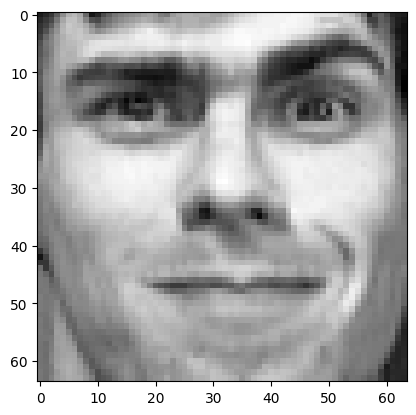

In [28]:
result = model.predict(X_test)

print('예측값:', result[31])
print('실제값:', Y_test[31])

# 1차원의 4096개 값 -> 2차원의 64*64개 값
plt.imshow(X_test[31].reshape(64, 64), cmap='gray')
plt.show()